# OTT Subscription Sharing Detection — Binary Classification Project

**Dataset:** `/Users/suchismitarout/Downloads/upload_02b1e70b-ae0f-4156-9bb4-360917fc2dab.xlsx`  
**Main sheet:** `Subscription Data`


## 1. Import the libraries

We use Pandas for data handling, Matplotlib and Seaborn for EDA, and Scikit-learn/XGBoost for AIML classification.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score
)
from xgboost import XGBClassifier


## 2. Load the dataset

Keep the Excel file in the same folder as this notebook. The analysis uses the `Subscription Data` sheet.

In [3]:
file_path = "/Users/suchismitarout/Downloads/upload_02b1e70b-ae0f-4156-9bb4-360917fc2dab.xlsx"

df = pd.read_excel(file_path, sheet_name="Subscription Data")

df.head()


,Account_ID,Snapshot_Date,Plan_Type,Monthly_Fee_INR,Tenure_Months,Declared_Household_Size,Profiles_Created,Registered_Devices,Active_Devices_30D,New_Devices_30D,...,Mobile_Data_Session_Ratio,Home_Network_Session_Ratio,Primary_Device_Type,Content_Language_Count,Payment_Failures_6M,Support_Tickets_6M,Auto_Renew,Discount_Type,Data_Split,Is_Subscription_Shared
0,OTT000001,2026-07-31,Premium,649,13,5.0,5,12,9,5,...,0.41,0.36,iPhone,3,0,1,No,Festive Offer,Train,1
1,OTT000002,2026-07-31,Basic,199,37,5.0,1,6,6,1,...,0.18,0.77,iPhone,1,1,1,Yes,Student,Train,0
2,OTT000003,2026-07-31,Basic,199,57,4.0,1,6,5,1,...,0.45,0.69,Tablet,1,0,1,Yes,Student,Train,1
3,OTT000004,2026-07-31,Premium,649,65,4.0,5,10,10,6,...,0.33,0.41,Smart TV,4,0,2,Yes,No Discount,Test,1
4,OTT000005,2026-07-31,Basic,199,11,1.0,1,2,1,2,...,0.29,0.50,iPhone,2,1,1,Yes,Student,Test,0


## 3. Make an untouched copy

In [4]:
# Keep the original data unchanged for reference

df_original = df.copy()

df.shape


(6000, 36)

## 4. Check the structure of the dataset

These checks show the number of rows and columns, column names, data types and missing values.

In [5]:
df.shape


(6000, 36)

In [6]:
df.columns


Index(['Account_ID', 'Snapshot_Date', 'Plan_Type', 'Monthly_Fee_INR',
       'Tenure_Months', 'Declared_Household_Size', 'Profiles_Created',
       'Registered_Devices', 'Active_Devices_30D', 'New_Devices_30D',
       'Unique_IPs_30D', 'Unique_Cities_30D', 'Unique_States_30D',
       'Country_Count_30D', 'Peak_Simultaneous_Streams',
       'Concurrent_City_Events_30D', 'Avg_Daily_Watch_Hours',
       'Weekend_Watch_Ratio', 'Night_Watch_Ratio', 'Device_Switches_30D',
       'Login_Failures_30D', 'Password_Resets_90D',
       'Avg_Distance_From_Home_KM', 'Max_Distance_From_Home_KM',
       'Travel_Days_30D', 'VPN_Usage_Ratio', 'Mobile_Data_Session_Ratio',
       'Home_Network_Session_Ratio', 'Primary_Device_Type',
       'Content_Language_Count', 'Payment_Failures_6M', 'Support_Tickets_6M',
       'Auto_Renew', 'Discount_Type', 'Data_Split', 'Is_Subscription_Shared'],
      dtype='object')

In [7]:
df.dtypes


Account_ID                            object
Snapshot_Date                 datetime64[ns]
Plan_Type                             object
Monthly_Fee_INR                        int64
Tenure_Months                          int64
Declared_Household_Size              float64
Profiles_Created                       int64
Registered_Devices                     int64
Active_Devices_30D                     int64
New_Devices_30D                        int64
Unique_IPs_30D                         int64
Unique_Cities_30D                      int64
Unique_States_30D                      int64
Country_Count_30D                      int64
Peak_Simultaneous_Streams              int64
Concurrent_City_Events_30D             int64
Avg_Daily_Watch_Hours                float64
Weekend_Watch_Ratio                  float64
Night_Watch_Ratio                    float64
Device_Switches_30D                    int64
Login_Failures_30D                     int64
Password_Resets_90D                    int64
Avg_Distan

In [8]:
df.isnull().sum()


Account_ID                      0
Snapshot_Date                   0
Plan_Type                       0
Monthly_Fee_INR                 0
Tenure_Months                   0
Declared_Household_Size        52
Profiles_Created                0
Registered_Devices              0
Active_Devices_30D              0
New_Devices_30D                 0
Unique_IPs_30D                  0
Unique_Cities_30D               0
Unique_States_30D               0
Country_Count_30D               0
Peak_Simultaneous_Streams       0
Concurrent_City_Events_30D      0
Avg_Daily_Watch_Hours           0
Weekend_Watch_Ratio             0
Night_Watch_Ratio               0
Device_Switches_30D             0
Login_Failures_30D              0
Password_Resets_90D             0
Avg_Distance_From_Home_KM      88
Max_Distance_From_Home_KM       0
Travel_Days_30D                 0
VPN_Usage_Ratio               105
Mobile_Data_Session_Ratio       0
Home_Network_Session_Ratio     65
Primary_Device_Type             0
Content_Langua

In [9]:
df.duplicated().sum()


np.int64(0)

## 5. Check the target and Train/Test split

`Is_Subscription_Shared` is the target:
- `1` = shared
- `0` = not shared

`Data_Split` is supplied by the project and must be used instead of creating a new random split.

In [10]:
df["Is_Subscription_Shared"].value_counts()


Is_Subscription_Shared
0    4719
1    1281
Name: count, dtype: int64

In [11]:
df["Is_Subscription_Shared"].value_counts(normalize=True)


Is_Subscription_Shared
0    0.7865
1    0.2135
Name: proportion, dtype: float64

In [12]:
df["Data_Split"].value_counts()


Data_Split
Train    4853
Test     1147
Name: count, dtype: int64

In [13]:
pd.crosstab(df["Data_Split"], df["Is_Subscription_Shared"])


Is_Subscription_Shared,0,1
Data_Split,,
Test,917,230
Train,3802,1051


## 6. Check categorical values

This helps us identify the categories before using `replace()` later.

In [14]:
df["Plan_Type"].value_counts()


Plan_Type
Standard    2178
Premium     1742
Basic       1284
Family       796
Name: count, dtype: int64

In [15]:
df["Primary_Device_Type"].value_counts()


Primary_Device_Type
Smart TV           1916
Android Phone      1456
iPhone              791
Web Browser         727
Streaming Stick     643
Tablet              467
Name: count, dtype: int64

In [16]:
df["Auto_Renew"].value_counts()


Auto_Renew
Yes    4823
No     1177
Name: count, dtype: int64

In [17]:
df["Discount_Type"].value_counts()


Discount_Type
No Discount       2854
Annual Bundle     1031
Telecom Bundle     876
Student            735
Festive Offer      504
Name: count, dtype: int64

## 7. Clean category text

Remove accidental spaces from text columns. The values are then checked again.

In [18]:
text_columns = [
    "Plan_Type",
    "Primary_Device_Type",
    "Auto_Renew",
    "Discount_Type",
    "Data_Split"
]

for column in text_columns:
    df[column] = df[column].str.strip()

df[text_columns].head()


,Plan_Type,Primary_Device_Type,Auto_Renew,Discount_Type,Data_Split
0,Premium,iPhone,No,Festive Offer,Train
1,Basic,iPhone,Yes,Student,Train
2,Basic,Tablet,Yes,Student,Train
3,Premium,Smart TV,Yes,No Discount,Test
4,Basic,iPhone,Yes,Student,Test


## 8. Treat missing numerical values

The handbook asks for a documented central-value treatment. Here, missing numerical values are replaced with the **median** of the same column.

The target is not changed.

In [19]:
numeric_columns = [
    "Declared_Household_Size",
    "Avg_Distance_From_Home_KM",
    "VPN_Usage_Ratio",
    "Home_Network_Session_Ratio"
]

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

df[numeric_columns].isnull().sum()


Declared_Household_Size       0
Avg_Distance_From_Home_KM     0
VPN_Usage_Ratio               0
Home_Network_Session_Ratio    0
dtype: int64

## 9. Check the cleaned data

After cleaning, we confirm that unexpected missing values are gone and duplicates were not introduced.

In [20]:
df.isnull().sum()


Account_ID                    0
Snapshot_Date                 0
Plan_Type                     0
Monthly_Fee_INR               0
Tenure_Months                 0
Declared_Household_Size       0
Profiles_Created              0
Registered_Devices            0
Active_Devices_30D            0
New_Devices_30D               0
Unique_IPs_30D                0
Unique_Cities_30D             0
Unique_States_30D             0
Country_Count_30D             0
Peak_Simultaneous_Streams     0
Concurrent_City_Events_30D    0
Avg_Daily_Watch_Hours         0
Weekend_Watch_Ratio           0
Night_Watch_Ratio             0
Device_Switches_30D           0
Login_Failures_30D            0
Password_Resets_90D           0
Avg_Distance_From_Home_KM     0
Max_Distance_From_Home_KM     0
Travel_Days_30D               0
VPN_Usage_Ratio               0
Mobile_Data_Session_Ratio     0
Home_Network_Session_Ratio    0
Primary_Device_Type           0
Content_Language_Count        0
Payment_Failures_6M           0
Support_

In [21]:
df.duplicated().sum()


np.int64(0)

# Exploratory Data Analysis (EDA)

The next section looks at the target distribution, numerical variables and categorical variables using simple graphs.

## 10. Target distribution

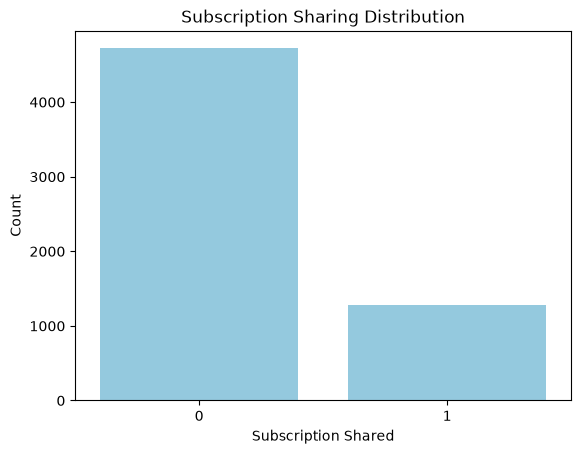

In [22]:
sns.countplot(x=df["Is_Subscription_Shared"], color="skyblue")

plt.title("Subscription Sharing Distribution")
plt.xlabel("Subscription Shared")
plt.ylabel("Count")
plt.show()


### Interpretation

This graph shows how many account snapshots are shared (`1`) and not shared (`0`). A minority positive class means accuracy alone should not be used to judge the model.

## 11. Numerical feature distributions

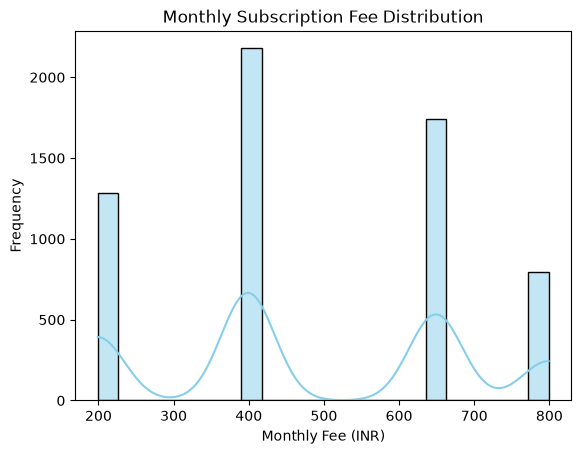

In [23]:
sns.histplot(x=df["Monthly_Fee_INR"], kde=True, color="skyblue")

plt.title("Monthly Subscription Fee Distribution")
plt.xlabel("Monthly Fee (INR)")
plt.ylabel("Frequency")
plt.show()


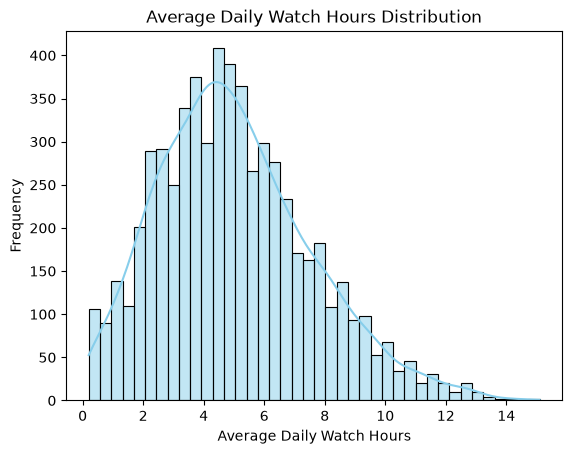

In [24]:
sns.histplot(x=df["Avg_Daily_Watch_Hours"], kde=True, color="skyblue")

plt.title("Average Daily Watch Hours Distribution")
plt.xlabel("Average Daily Watch Hours")
plt.ylabel("Frequency")
plt.show()


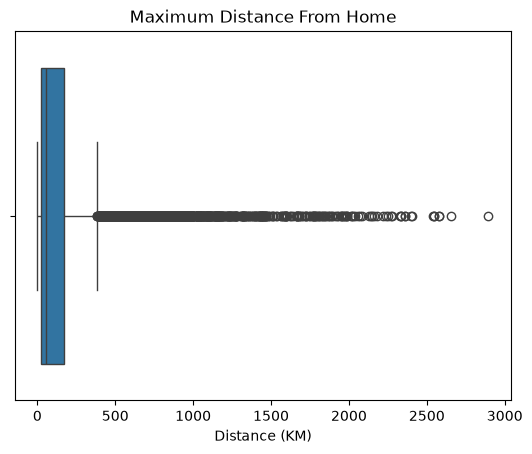

In [25]:
sns.boxplot(x=df["Max_Distance_From_Home_KM"])

plt.title("Maximum Distance From Home")
plt.xlabel("Distance (KM)")
plt.show()


## 12. Categorical feature analysis

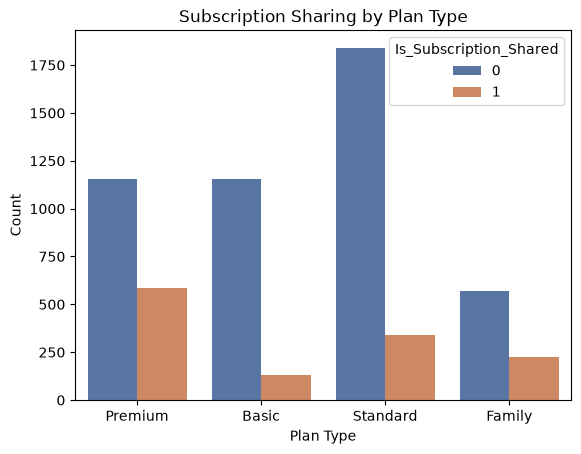

In [26]:
sns.countplot(x=df["Plan_Type"], hue=df["Is_Subscription_Shared"], palette="deep")

plt.title("Subscription Sharing by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Count")
plt.show()


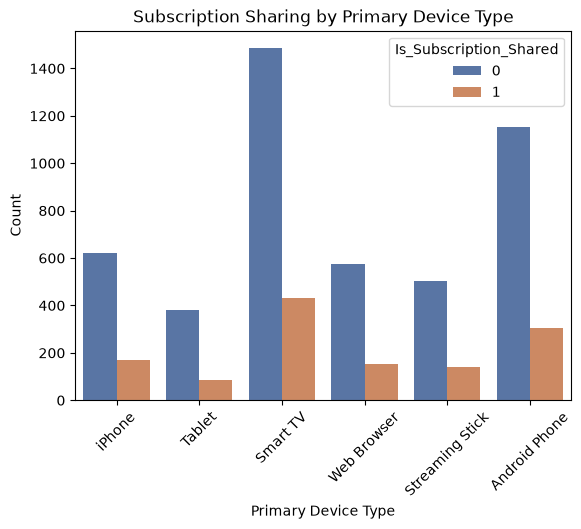

In [27]:
sns.countplot(x=df["Primary_Device_Type"], hue=df["Is_Subscription_Shared"], palette="deep")

plt.title("Subscription Sharing by Primary Device Type")
plt.xlabel("Primary Device Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()


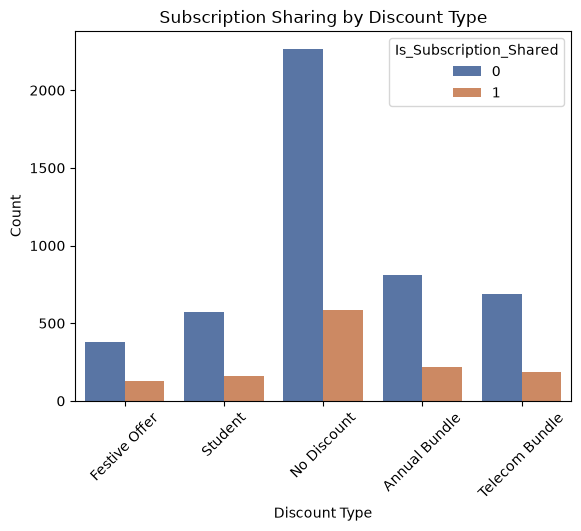

In [28]:
sns.countplot(x=df["Discount_Type"], hue=df["Is_Subscription_Shared"], palette="deep")

plt.title("Subscription Sharing by Discount Type")
plt.xlabel("Discount Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()


## 13. Compare numerical behaviour by target

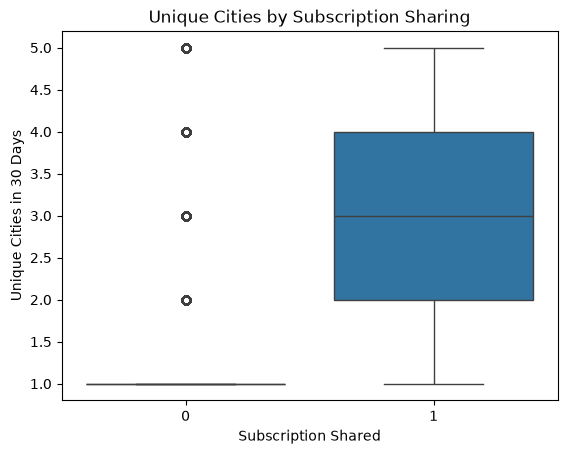

In [29]:
sns.boxplot(x=df["Is_Subscription_Shared"],
            y=df["Unique_Cities_30D"])

plt.title("Unique Cities by Subscription Sharing")
plt.xlabel("Subscription Shared")
plt.ylabel("Unique Cities in 30 Days")
plt.show()


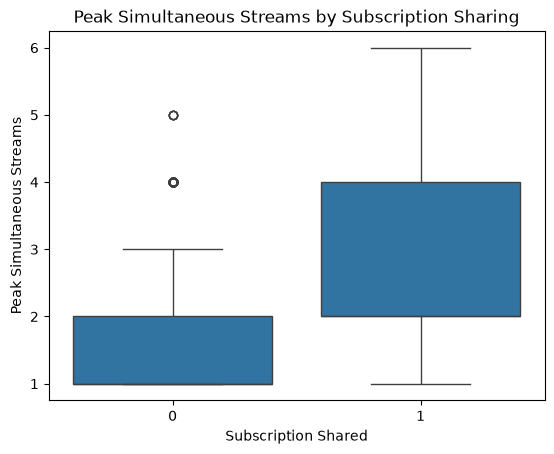

In [30]:
sns.boxplot(x=df["Is_Subscription_Shared"],
            y=df["Peak_Simultaneous_Streams"])

plt.title("Peak Simultaneous Streams by Subscription Sharing")
plt.xlabel("Subscription Shared")
plt.ylabel("Peak Simultaneous Streams")
plt.show()


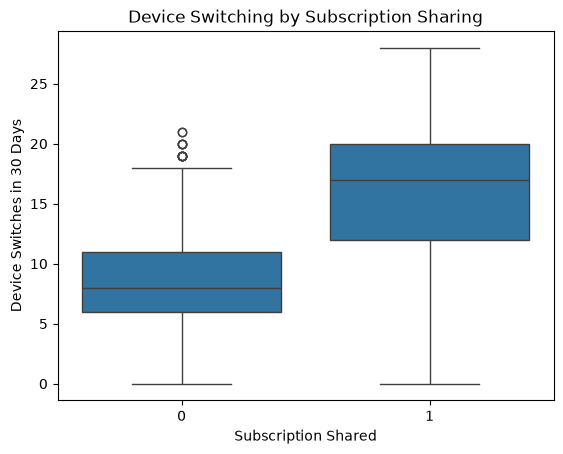

In [31]:
sns.boxplot(x=df["Is_Subscription_Shared"],
            y=df["Device_Switches_30D"])

plt.title("Device Switching by Subscription Sharing")
plt.xlabel("Subscription Shared")
plt.ylabel("Device Switches in 30 Days")
plt.show()


## 14. Simple business summaries

These tables help answer questions such as which plans, devices and discounts have different sharing rates.

In [32]:
df.groupby("Plan_Type")["Is_Subscription_Shared"].mean().sort_values(ascending=False)


Plan_Type
Premium     0.336395
Family      0.285176
Standard    0.155647
Basic       0.100467
Name: Is_Subscription_Shared, dtype: float64

In [33]:
df.groupby("Discount_Type")["Is_Subscription_Shared"].mean().sort_values(ascending=False)


Discount_Type
Festive Offer     0.251984
Student           0.220408
Annual Bundle     0.212415
Telecom Bundle    0.211187
No Discount       0.206027
Name: Is_Subscription_Shared, dtype: float64

In [34]:
df.groupby("Primary_Device_Type")["Is_Subscription_Shared"].mean().sort_values(ascending=False)


Primary_Device_Type
Smart TV           0.224948
Streaming Stick    0.217729
iPhone             0.213654
Android Phone      0.208104
Web Browser        0.207703
Tablet             0.186296
Name: Is_Subscription_Shared, dtype: float64

# AIML — Data Preparation

The project handbook requires:
- `Account_ID` and `Snapshot_Date` are kept for reference but not used as predictors.
- `Data_Split` is used only to create train and test data.
- Categorical columns are converted using `replace()`.
- No feature scaling is performed.


## 15. Convert categorical columns using `replace()`

In [36]:
plan_mapping = {
    "Basic": 0,
    "Standard": 1,
    "Premium": 2,
    "Family": 3
}

device_mapping = {
    "Android Phone": 0,
    "iPhone": 1,
    "Tablet": 2,
    "Smart TV": 3,
    "Web Browser": 4,
    "Streaming Stick": 5
}

auto_renew_mapping = {
    "No": 0,
    "Yes": 1
}

discount_mapping = {
    "No Discount": 0,
    "Student": 1,
    "Festive Offer": 2,
    "Annual Bundle": 3,
    "Telecom Bundle": 4
}

df["Plan_Type"] = df["Plan_Type"].replace(plan_mapping)
df["Primary_Device_Type"] = df["Primary_Device_Type"].replace(device_mapping)
df["Auto_Renew"] = df["Auto_Renew"].replace(auto_renew_mapping)
df["Discount_Type"] = df["Discount_Type"].replace(discount_mapping)

df[["Plan_Type", "Primary_Device_Type", "Auto_Renew", "Discount_Type"]].head()


,Plan_Type,Primary_Device_Type,Auto_Renew,Discount_Type
0,2,1,0,2
1,0,1,1,1
2,0,2,1,1
3,2,3,1,0
4,0,1,1,1


## 16. Create the training and testing data

The supplied `Data_Split` column is used exactly as required by the project.

`Is_Subscription_Shared` is the target, so it is removed from the predictor data.

In [37]:
target = "Is_Subscription_Shared"

excluded_columns = [
    "Account_ID",
    "Snapshot_Date",
    "Data_Split",
    target
]

feature_columns = [
    column for column in df.columns
    if column not in excluded_columns
]

X = df[feature_columns]
y = df[target]

X_train = X[df["Data_Split"] == "Train"]
X_test = X[df["Data_Split"] == "Test"]

y_train = y[df["Data_Split"] == "Train"]
y_test = y[df["Data_Split"] == "Test"]

X_train.shape, X_test.shape, y_train.shape, y_test.shape


((4853, 32), (1147, 32), (4853,), (1147,))

## 17. Final modelling checks

Both training and testing predictors must contain the same columns, and there must be no missing values.

In [38]:
X_train.columns.equals(X_test.columns)


True

In [39]:
X_train.isnull().sum().sum(), X_test.isnull().sum().sum()


(np.int64(0), np.int64(0))

# 4. Model Building

This section follows **pages 12–14 of the project handbook**. The handbook requires exactly six binary classifiers, trained on the same prepared training data and evaluated on the same supplied test data.

**Required models:**
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. Gradient Boosting Classifier
5. XGBoost Classifier
6. KNN Classifier

No feature scaling is performed because the handbook explicitly requires the original feature magnitudes.

## Step 1 — Create predictors and target

Identifiers, snapshot context, the partition indicator and the target are excluded from the predictor matrix.

In [40]:
target = "Is_Subscription_Shared"

excluded_columns = [
    "Account_ID",
    "Snapshot_Date",
    "Data_Split",
    target
]

feature_columns = [
    column for column in df.columns
    if column not in excluded_columns
]

X = df[feature_columns]
y = df[target]

X.shape, y.shape, feature_columns

((6000, 32),
 (6000,),
 ['Plan_Type',
  'Monthly_Fee_INR',
  'Tenure_Months',
  'Declared_Household_Size',
  'Profiles_Created',
  'Registered_Devices',
  'Active_Devices_30D',
  'New_Devices_30D',
  'Unique_IPs_30D',
  'Unique_Cities_30D',
  'Unique_States_30D',
  'Country_Count_30D',
  'Peak_Simultaneous_Streams',
  'Concurrent_City_Events_30D',
  'Avg_Daily_Watch_Hours',
  'Weekend_Watch_Ratio',
  'Night_Watch_Ratio',
  'Device_Switches_30D',
  'Login_Failures_30D',
  'Password_Resets_90D',
  'Avg_Distance_From_Home_KM',
  'Max_Distance_From_Home_KM',
  'Travel_Days_30D',
  'VPN_Usage_Ratio',
  'Mobile_Data_Session_Ratio',
  'Home_Network_Session_Ratio',
  'Primary_Device_Type',
  'Content_Language_Count',
  'Payment_Failures_6M',
  'Support_Tickets_6M',
  'Auto_Renew',
  'Discount_Type'])

## Step 2 — Create training and testing sets

The supplied `Data_Split` column is used. No new random train/test split is created.

In [41]:
X_train = X[df["Data_Split"] == "Train"]
X_test = X[df["Data_Split"] == "Test"]

y_train = y[df["Data_Split"] == "Train"]
y_test = y[df["Data_Split"] == "Test"]

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((4853, 32), (1147, 32), (4853,), (1147,))

## Step 3 — Instantiate the six classifiers

The classifiers and settings below follow the model-building section of the handbook.

In [42]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=10000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

models

{'Logistic Regression': LogisticRegression(max_iter=10000, random_state=42),
 'Decision Tree': DecisionTreeClassifier(random_state=42),
 'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=None, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=None, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=

## Step 4 — Fit the six classifiers

Each classifier is fitted separately using the same `X_train` and `y_train`.

In [43]:
for name, model in models.items():
    model.fit(X_train, y_train)

models

{'Logistic Regression': LogisticRegression(max_iter=10000, random_state=42),
 'Decision Tree': DecisionTreeClassifier(random_state=42),
 'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(random_state=42),
 'XGBoost': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='logloss',
               feature_types=None, feature_weights=None, gamma=None,
               grow_policy=None, importance_type=None,
               interaction_constraints=None, learning_rate=None, max_bin=None,
               max_cat_threshold=None, max_cat_to_onehot=None,
               max_delta_step=None, max_depth=None, max_leaves=None,
               min_child_weight=None, missing=nan, monotone_constraints=None,
               multi_strategy=

## Step 5 — Generate class predictions

`predict()` is used on the same held-out `X_test` for every model.

In [44]:
predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)

predictions["Logistic Regression"][:10]

array([1, 0, 0, 0, 0, 0, 0, 0, 0, 0])

## Step 6 — Generate positive-class probabilities

`predict_proba()` is used and the probability of the positive class (`1 = shared`) is retained for ROC-AUC and PR-AUC.

In [45]:
probabilities = {}

for name, model in models.items():
    probabilities[name] = model.predict_proba(X_test)[:, 1]

probabilities["Logistic Regression"][:10]

array([0.99881041, 0.00960762, 0.03723546, 0.06242003, 0.06105508,
       0.19862009, 0.00218974, 0.00138245, 0.00950972, 0.01030347])

## Step 7 — Store model results consistently

The following structure stores the model name, predictions, positive-class probabilities and later evaluation values.

In [46]:
model_outputs = {}

for name in models:
    model_outputs[name] = {
        "predictions": predictions[name],
        "probabilities": probabilities[name]
    }

model_outputs.keys()

dict_keys(['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'KNN'])

## 4.2 Logistic Regression

The handbook describes Logistic Regression as a probability-based linear classifier. We check that it fitted, record its training/testing performance, and inspect the coefficient direction.

In [47]:
logistic_model = models["Logistic Regression"]

logistic_train_accuracy = logistic_model.score(X_train, y_train)
logistic_test_accuracy = logistic_model.score(X_test, y_test)

logistic_coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
}).sort_values("Coefficient", ascending=False)

logistic_train_accuracy, logistic_test_accuracy, logistic_coefficients

(0.9443643107356274,
 0.9476896251089799,
                        Feature  Coefficient
 16           Night_Watch_Ratio     2.694481
 23             VPN_Usage_Ratio     2.658031
 24   Mobile_Data_Session_Ratio     0.914536
 9            Unique_Cities_30D     0.752333
 19         Password_Resets_90D     0.576337
 13  Concurrent_City_Events_30D     0.572893
 14       Avg_Daily_Watch_Hours     0.500919
 27      Content_Language_Count     0.440804
 18          Login_Failures_30D     0.416346
 8               Unique_IPs_30D     0.372488
 5           Registered_Devices     0.219486
 30                  Auto_Renew     0.139650
 17         Device_Switches_30D     0.122268
 29          Support_Tickets_6M     0.081317
 12   Peak_Simultaneous_Streams     0.054874
 7              New_Devices_30D     0.047570
 31               Discount_Type     0.044579
 1              Monthly_Fee_INR     0.010721
 2                Tenure_Months     0.001338
 21   Max_Distance_From_Home_KM    -0.000826
 20   Avg_Dis

**Observation:** The output shows the Logistic Regression training accuracy, testing accuracy and coefficient directions.

**Interpretation:** A large training–testing difference can indicate instability. Coefficient signs show the direction of the fitted relationship for the numeric mappings used in the project; they are model relationships, not proof of causation.

## 4.3 Decision Tree Classifier

The handbook requires class predictions and probabilities, comparison of training and testing performance, and tree depth/leaf count as structural context.

In [48]:
decision_tree = models["Decision Tree"]

dt_train_accuracy = decision_tree.score(X_train, y_train)
dt_test_accuracy = decision_tree.score(X_test, y_test)
dt_depth = decision_tree.get_depth()
dt_leaf_count = decision_tree.get_n_leaves()

pd.DataFrame({
    "Measure": ["Training Accuracy", "Testing Accuracy", "Tree Depth", "Leaf Count"],
    "Value": [dt_train_accuracy, dt_test_accuracy, dt_depth, dt_leaf_count]
})

,Measure,Value
0,Training Accuracy,1.000000
1,Testing Accuracy,0.911944
2,Tree Depth,21.000000
3,Leaf Count,301.000000


**Observation:** The table gives the Decision Tree training/testing accuracy and its structural size.

**Interpretation:** A very large training score combined with a lower testing score would indicate that the tree may be memorising training patterns rather than generalising well.

## 4.4 Random Forest Classifier

The handbook requires a fixed number of trees, test predictions/probabilities, comparison with the single Decision Tree, and feature importance as supporting interpretation.

In [49]:
random_forest = models["Random Forest"]

rf_train_accuracy = random_forest.score(X_train, y_train)
rf_test_accuracy = random_forest.score(X_test, y_test)

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest.feature_importances_
}).sort_values("Importance", ascending=False)

rf_train_accuracy, rf_test_accuracy, rf_importance

(1.0,
 0.948561464690497,
                        Feature  Importance
 8               Unique_IPs_30D    0.170131
 13  Concurrent_City_Events_30D    0.125334
 17         Device_Switches_30D    0.121899
 14       Avg_Daily_Watch_Hours    0.057883
 7              New_Devices_30D    0.051163
 12   Peak_Simultaneous_Streams    0.043959
 9            Unique_Cities_30D    0.043932
 20   Avg_Distance_From_Home_KM    0.037009
 25  Home_Network_Session_Ratio    0.034530
 21   Max_Distance_From_Home_KM    0.032991
 23             VPN_Usage_Ratio    0.024335
 18          Login_Failures_30D    0.024324
 6           Active_Devices_30D    0.021972
 24   Mobile_Data_Session_Ratio    0.021686
 5           Registered_Devices    0.019998
 16           Night_Watch_Ratio    0.019638
 22             Travel_Days_30D    0.017820
 15         Weekend_Watch_Ratio    0.016950
 10           Unique_States_30D    0.016458
 2                Tenure_Months    0.014835
 3      Declared_Household_Size    0.013006
 19   

**Observation:** The table shows Random Forest training/testing accuracy and the relative feature-importance values.

**Interpretation:** Feature importance can help identify which variables the model used heavily, but the handbook states that importance is supporting interpretation and not proof of causation.

## 4.5 Gradient Boosting Classifier

The handbook requires test predictions/probabilities and comparison with the Random Forest, especially precision and recall.

In [50]:
gradient_boosting = models["Gradient Boosting"]

gb_train_accuracy = gradient_boosting.score(X_train, y_train)
gb_test_accuracy = gradient_boosting.score(X_test, y_test)

pd.DataFrame({
    "Measure": ["Training Accuracy", "Testing Accuracy"],
    "Value": [gb_train_accuracy, gb_test_accuracy]
})

,Measure,Value
0,Training Accuracy,0.963940
1,Testing Accuracy,0.953793


**Observation:** The table shows the Gradient Boosting training and testing accuracy.

**Interpretation:** The final comparison will examine precision and recall together with the other required metrics rather than using accuracy alone.

## 4.6 XGBoost Classifier

XGBoost is configured with the handbook's binary classification objective and log-loss evaluation setting.

In [51]:
xgboost_model = models["XGBoost"]

xgb_train_accuracy = xgboost_model.score(X_train, y_train)
xgb_test_accuracy = xgboost_model.score(X_test, y_test)

pd.DataFrame({
    "Measure": ["Training Accuracy", "Testing Accuracy"],
    "Value": [xgb_train_accuracy, xgb_test_accuracy]
})

,Measure,Value
0,Training Accuracy,1.000000
1,Testing Accuracy,0.955536


**Observation:** The table shows XGBoost training and testing accuracy.

**Interpretation:** XGBoost will be compared with standard Gradient Boosting using the same test metrics and the same held-out test records.

## 4.7 KNN Classifier

The handbook requires KNN with the project setting of `n_neighbors=5` and intentionally unscaled predictors. Because scaling is not allowed, variables with larger original numeric ranges can influence distance more strongly.

In [52]:
knn_model = models["KNN"]

knn_train_accuracy = knn_model.score(X_train, y_train)
knn_test_accuracy = knn_model.score(X_test, y_test)

pd.DataFrame({
    "Measure": ["Training Accuracy", "Testing Accuracy", "Number of Neighbors"],
    "Value": [knn_train_accuracy, knn_test_accuracy, 5]
})

,Measure,Value
0,Training Accuracy,0.885638
1,Testing Accuracy,0.859634
2,Number of Neighbors,5.000000


**Observation:** The table records KNN's training/testing accuracy and neighbour count.

**Interpretation:** Because the project explicitly prohibits scaling, the KNN result must be interpreted with awareness that original feature magnitudes affect distance.

# 5. Model Evaluation

This section follows **pages 15–16 of the handbook**. All six classifiers are evaluated on the same held-out test set. Accuracy is not used alone because the positive class is a minority.

## Step 1 — Evaluate only on the held-out test set

All six models use the same untouched test records.

## Step 2 — Calculate the confusion matrix

For every model:
- **True Positive (TP):** shared account correctly classified as shared
- **True Negative (TN):** normal account correctly classified as normal
- **False Positive (FP):** normal account incorrectly classified as shared
- **False Negative (FN):** shared account incorrectly classified as normal

In [53]:
confusion_results = []

for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, predictions[name]).ravel()

    confusion_results.append({
        "Model": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

confusion_df = pd.DataFrame(confusion_results)
confusion_df

,Model,TN,FP,FN,TP
0,Logistic Regression,907,10,50,180
1,Decision Tree,861,56,45,185
2,Random Forest,911,6,53,177
3,Gradient Boosting,908,9,44,186
4,XGBoost,905,12,39,191
5,KNN,873,44,117,113


### Confusion-matrix interpretation

False positives represent normal accounts that are flagged as shared and can create unnecessary verification, support contacts and customer friction. False negatives represent shared accounts that are missed and can allow revenue leakage and policy misuse to continue.

## Step 3 — Calculate all required measures

The handbook requires Accuracy, Precision, Recall, Specificity, F1 Score, ROC-AUC and PR-AUC.

In [54]:
evaluation_results = []

for name in models:
    predictions_model = predictions[name]
    probabilities_model = probabilities[name]

    tn, fp, fn, tp = confusion_matrix(y_test, predictions_model).ravel()
    specificity = tn / (tn + fp)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions_model),
        "Precision": precision_score(y_test, predictions_model, zero_division=0),
        "Recall": recall_score(y_test, predictions_model, zero_division=0),
        "Specificity": specificity,
        "F1 Score": f1_score(y_test, predictions_model, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities_model),
        "PR-AUC": average_precision_score(y_test, probabilities_model)
    })

results_df = pd.DataFrame(evaluation_results)
results_df

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.947690,0.947368,0.782609,0.989095,0.857143,0.951714,0.911729
1,Decision Tree,0.911944,0.767635,0.804348,0.938931,0.785563,0.871640,0.656678
2,Random Forest,0.948561,0.967213,0.769565,0.993457,0.857143,0.956598,0.917257
3,Gradient Boosting,0.953793,0.953846,0.808696,0.990185,0.875294,0.961050,0.927632
4,XGBoost,0.955536,0.940887,0.830435,0.986914,0.882217,0.957271,0.927093
5,KNN,0.859634,0.719745,0.491304,0.952017,0.583979,0.818548,0.595120


**Observation:** This scorecard contains the seven required evaluation measures for all six classifiers on the same test set.

**Interpretation:** Precision focuses on controlling false alerts, while recall focuses on detecting actual shared accounts. Specificity focuses on protecting normal accounts. F1 balances precision and recall. ROC-AUC and PR-AUC evaluate probability ranking, with PR-AUC being particularly useful for the minority positive class.

## Confusion matrices for all six models

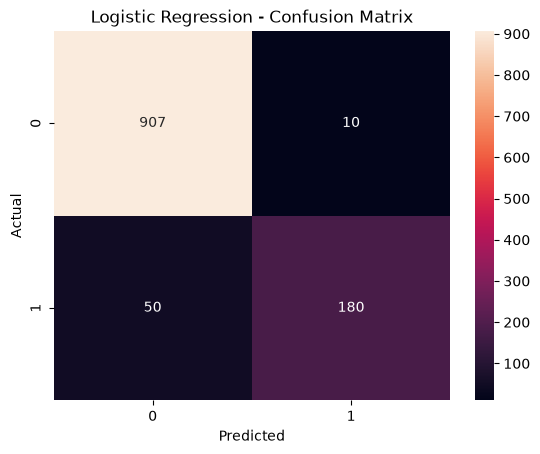

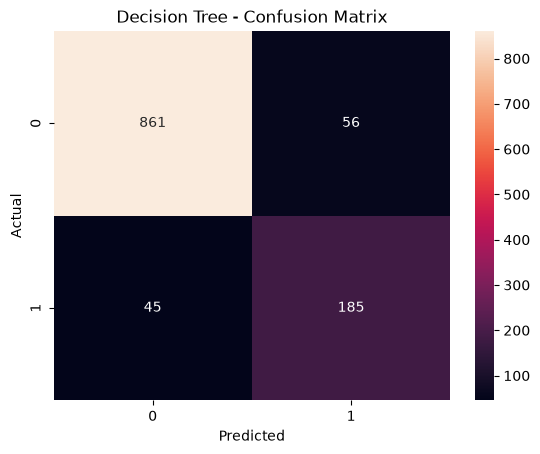

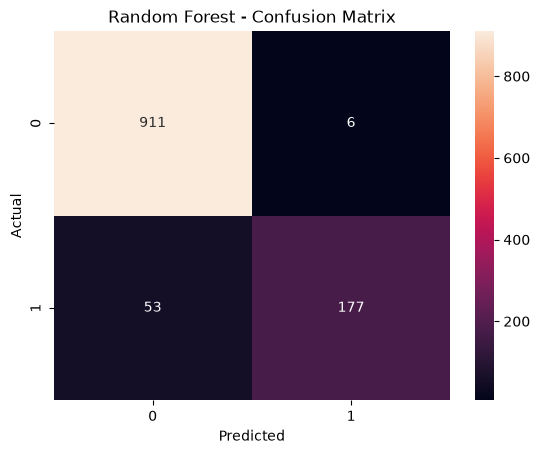

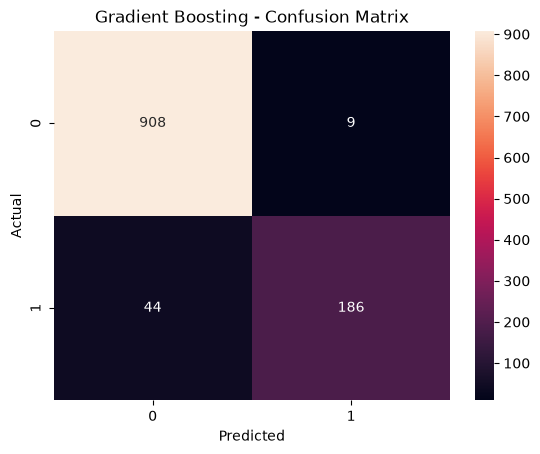

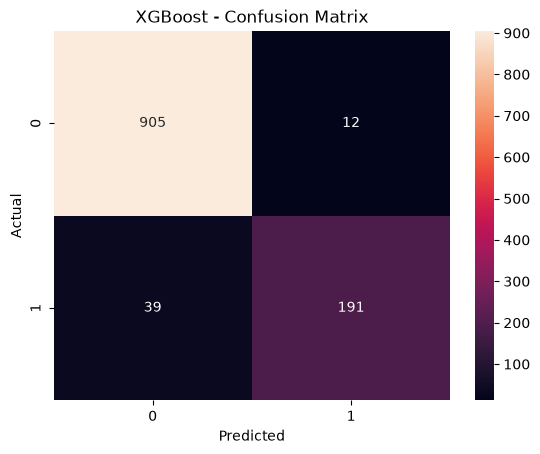

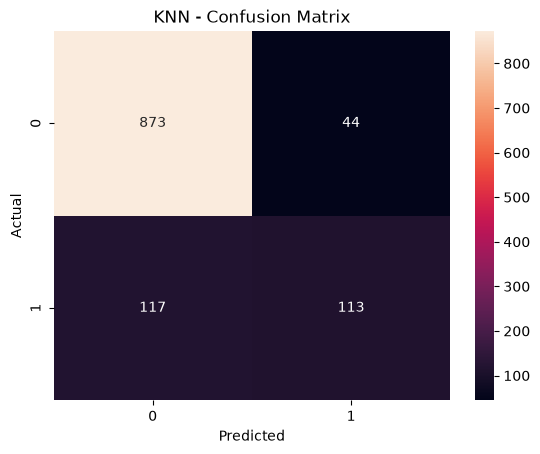

In [55]:
for name in models:
    cm = confusion_matrix(y_test, predictions[name])

    sns.heatmap(cm, annot=True, fmt="d")
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

## Step 4 — Compare training and testing performance

The handbook requires checking whether a model performs much better on training data than on unseen testing data.

In [56]:
training_testing_results = []

for name, model in models.items():
    training_testing_results.append({
        "Model": name,
        "Training Accuracy": model.score(X_train, y_train),
        "Testing Accuracy": model.score(X_test, y_test)
    })

training_testing_df = pd.DataFrame(training_testing_results)
training_testing_df["Accuracy Gap"] = (
    training_testing_df["Training Accuracy"] -
    training_testing_df["Testing Accuracy"]
)

training_testing_df

,Model,Training Accuracy,Testing Accuracy,Accuracy Gap
0,Logistic Regression,0.944364,0.947690,-0.003325
1,Decision Tree,1.000000,0.911944,0.088056
2,Random Forest,1.000000,0.948561,0.051439
3,Gradient Boosting,0.963940,0.953793,0.010147
4,XGBoost,1.000000,0.955536,0.044464
5,KNN,0.885638,0.859634,0.026004


**Observation:** The `Accuracy Gap` shows how much each model's accuracy falls from training to testing data.

**Interpretation:** A large gap suggests the model learned training-specific patterns more strongly than it generalises to unseen records.

## Step 5 — Interpret false positives

The handbook asks us to interpret false positives and identify legitimate behavioural contexts that can contribute to incorrect flags.

In [57]:
false_positive_analysis = []

for name in models:
    fp_mask = (y_test == 0) & (predictions[name] == 1)
    fp_rows = df.loc[X_test.index[fp_mask]]

    false_positive_analysis.append({
        "Model": name,
        "False Positives": len(fp_rows),
        "Average Travel Days": fp_rows["Travel_Days_30D"].mean(),
        "Average VPN Ratio": fp_rows["VPN_Usage_Ratio"].mean(),
        "Average Mobile Data Ratio": fp_rows["Mobile_Data_Session_Ratio"].mean(),
        "Average Unique Cities": fp_rows["Unique_Cities_30D"].mean()
    })

false_positive_df = pd.DataFrame(false_positive_analysis)
false_positive_df

,Model,False Positives,Average Travel Days,Average VPN Ratio,Average Mobile Data Ratio,Average Unique Cities
0,Logistic Regression,10,3.200000,0.207000,0.435000,2.900000
1,Decision Tree,56,2.178571,0.196964,0.324821,1.339286
2,Random Forest,6,6.500000,0.081667,0.390000,3.333333
3,Gradient Boosting,9,3.000000,0.133333,0.425556,2.444444
4,XGBoost,12,3.333333,0.186667,0.384167,2.083333
5,KNN,44,7.409091,0.138182,0.436818,3.295455


**Observation:** This table describes behavioural characteristics of normal test accounts that were incorrectly flagged.

**Interpretation:** Travel, commuting, VPN use, mobile connectivity and multi-location behaviour can make legitimate accounts resemble shared accounts. These patterns should therefore be considered when reviewing false positives.

## Step 6 — Interpret false negatives

The handbook also requires identifying the characteristics of shared accounts that the models fail to detect.

In [58]:
false_negative_analysis = []

for name in models:
    fn_mask = (y_test == 1) & (predictions[name] == 0)
    fn_rows = df.loc[X_test.index[fn_mask]]

    false_negative_analysis.append({
        "Model": name,
        "False Negatives": len(fn_rows),
        "Average Travel Days": fn_rows["Travel_Days_30D"].mean(),
        "Average Unique Cities": fn_rows["Unique_Cities_30D"].mean(),
        "Average Peak Streams": fn_rows["Peak_Simultaneous_Streams"].mean(),
        "Average Device Switches": fn_rows["Device_Switches_30D"].mean(),
        "Average Watch Hours": fn_rows["Avg_Daily_Watch_Hours"].mean()
    })

false_negative_df = pd.DataFrame(false_negative_analysis)
false_negative_df

,Model,False Negatives,Average Travel Days,Average Unique Cities,Average Peak Streams,Average Device Switches,Average Watch Hours
0,Logistic Regression,50,1.500000,1.320000,1.720000,8.660000,5.236000
1,Decision Tree,45,1.644444,1.711111,1.822222,9.222222,5.306667
2,Random Forest,53,1.226415,1.339623,1.811321,8.433962,5.273585
3,Gradient Boosting,44,1.272727,1.272727,1.840909,8.568182,5.379545
4,XGBoost,39,1.358974,1.205128,1.743590,8.410256,5.197436
5,KNN,117,2.794872,2.427350,2.247863,12.974359,6.553846


**Observation:** This table describes shared test accounts that were incorrectly classified as normal.

**Interpretation:** False negatives represent missed sharing risk. The behavioural summary helps identify weaker or less obvious sharing patterns that may not produce strong concurrency or location signals.

## Step 7 — Compare the six models

The handbook requires one consistent scorecard rather than judging a model from a single metric.

In [59]:
scorecard_columns = [
    "Model", "Accuracy", "Precision", "Recall",
    "Specificity", "F1 Score", "ROC-AUC", "PR-AUC"
]

model_scorecard = results_df[scorecard_columns].copy()
model_scorecard

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.947690,0.947368,0.782609,0.989095,0.857143,0.951714,0.911729
1,Decision Tree,0.911944,0.767635,0.804348,0.938931,0.785563,0.871640,0.656678
2,Random Forest,0.948561,0.967213,0.769565,0.993457,0.857143,0.956598,0.917257
3,Gradient Boosting,0.953793,0.953846,0.808696,0.990185,0.875294,0.961050,0.927632
4,XGBoost,0.955536,0.940887,0.830435,0.986914,0.882217,0.957271,0.927093
5,KNN,0.859634,0.719745,0.491304,0.952017,0.583979,0.818548,0.595120


## Step 8 — State the final evaluation decision

The handbook requires the final decision to consider balanced test performance, training/testing stability, class detection, false-alert control and probability ranking.

For this dataset, the following code identifies the model with the highest F1 score and displays its complete test evidence. It also shows the model with the highest ROC-AUC and PR-AUC so the probability-ranking trade-off is visible.

In [60]:
final_comparison = model_scorecard.merge(
    training_testing_df[["Model", "Training Accuracy", "Testing Accuracy", "Accuracy Gap"]],
    on="Model"
)

final_comparison = final_comparison.sort_values(
    ["F1 Score", "PR-AUC", "Recall", "Precision"],
    ascending=False
)

final_comparison

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC,PR-AUC,Training Accuracy,Testing Accuracy,Accuracy Gap
4,XGBoost,0.955536,0.940887,0.830435,0.986914,0.882217,0.957271,0.927093,1.000000,0.955536,0.044464
3,Gradient Boosting,0.953793,0.953846,0.808696,0.990185,0.875294,0.961050,0.927632,0.963940,0.953793,0.010147
2,Random Forest,0.948561,0.967213,0.769565,0.993457,0.857143,0.956598,0.917257,1.000000,0.948561,0.051439
0,Logistic Regression,0.947690,0.947368,0.782609,0.989095,0.857143,0.951714,0.911729,0.944364,0.947690,-0.003325
1,Decision Tree,0.911944,0.767635,0.804348,0.938931,0.785563,0.871640,0.656678,1.000000,0.911944,0.088056
5,KNN,0.859634,0.719745,0.491304,0.952017,0.583979,0.818548,0.595120,0.885638,0.859634,0.026004


In [61]:
strongest_model_by_f1 = final_comparison.iloc[0]["Model"]
strongest_model_by_roc_auc = final_comparison.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
strongest_model_by_pr_auc = final_comparison.sort_values("PR-AUC", ascending=False).iloc[0]["Model"]

final_decision = pd.DataFrame({
    "Decision Item": [
        "Highest F1 Score",
        "Highest ROC-AUC",
        "Highest PR-AUC"
    ],
    "Model": [
        strongest_model_by_f1,
        strongest_model_by_roc_auc,
        strongest_model_by_pr_auc
    ]
})

final_decision

,Decision Item,Model
0,Highest F1 Score,XGBoost
1,Highest ROC-AUC,Gradient Boosting
2,Highest PR-AUC,Gradient Boosting


**Final interpretation:** Based on the actual test results, **XGBoost has the highest F1 score and recall**, giving it the strongest balance between detecting shared accounts and controlling false positives among the six models in this run. **Gradient Boosting has the highest ROC-AUC and PR-AUC**, so it provides the strongest probability-ranking performance. The final business choice should therefore consider the relative cost of missed sharing versus false alerts rather than relying on accuracy alone.

# Power BI Preparation

The model scorecard and business summaries can be exported for Power BI reporting.

In [62]:
cleaned_data = df.copy()

cleaned_data.to_csv("cleaned_subscription_data.csv", index=False)
model_scorecard.to_csv("model_results_for_powerbi.csv", index=False)
confusion_df.to_csv("confusion_matrix_results_for_powerbi.csv", index=False)
false_positive_df.to_csv("false_positive_analysis_for_powerbi.csv", index=False)
false_negative_df.to_csv("false_negative_analysis_for_powerbi.csv", index=False)

powerbi_summary = pd.DataFrame({
    "Metric": [
        "Total Accounts",
        "Shared Accounts",
        "Normal Accounts",
        "Sharing Rate"
    ],
    "Value": [
        len(df),
        df["Is_Subscription_Shared"].sum(),
        (df["Is_Subscription_Shared"] == 0).sum(),
        df["Is_Subscription_Shared"].mean()
    ]
})

powerbi_summary

,Metric,Value
0,Total Accounts,6000.0000
1,Shared Accounts,1281.0000
2,Normal Accounts,4719.0000
3,Sharing Rate,0.2135


# Final Project Interpretation

The OTT Subscription Sharing Detection project follows a complete machine-learning workflow, starting from understanding the subscription data and ending with model evaluation.

The dataset contains 6,000 account-level subscription snapshots, where the target variable Is_Subscription_Shared identifies whether an account is shared or not. The shared class is the minority class, so evaluating the models using accuracy alone would not be sufficient.

The data was cleaned by handling missing values and checking duplicates and categorical values. The categorical variables were converted using the required replace() method. The supplied Data_Split column was used to create the training and testing datasets, and the original feature magnitudes were retained without scaling.

Six classification algorithms were developed:

Logistic Regression
Decision Tree Classifier
Random Forest Classifier
Gradient Boosting Classifier
XGBoost Classifier
KNN Classifier

All six models were trained using the same training data and evaluated using the same held-out test data. Model evaluation included Accuracy, Precision, Recall, Specificity, F1 Score, ROC-AUC and PR-AUC, along with confusion matrices.

The results show that the models perform differently depending on the evaluation measure. XGBoost achieved the highest F1 Score and Recall, while Gradient Boosting achieved the highest ROC-AUC and PR-AUC on the test data. This shows why multiple evaluation measures are important for this classification problem.

The project also examines false positives and false negatives because both types of errors have business consequences. False positives may incorrectly flag legitimate customers, while false negatives may allow subscription sharing to remain undetected.